<div align="center">

# Deep Convolutional GAN (DCGAN) on Fashion-MNIST
### Practical 4 · Generative Adversarial Networks
**PRN: 202401110045**

</div>

---

## Table of Contents
1. [Aim & Approach](#1)
2. [Environment Setup](#2)
3. [Dataset & Exploratory Analysis](#3)
4. [DCGAN Architecture](#4)
5. [Evaluation Toolkit (Fréchet Distance with a Fashion-MNIST feature extractor)](#5)
6. [Adversarial Training](#6)
7. [Loss Curve Analysis](#7)
8. [Generated Image Quality Analysis](#8)
9. [3D Analysis](#9)
10. [Latent Space Exploration](#10)
11. [Quantitative Summary & Automated Findings](#11)
12. [Conclusion](#12)

---

<a id="1"></a>
## 1. Aim & Approach

**Aim:** Implement and train a Deep Convolutional GAN (DCGAN), generate synthetic images with the trained Generator, and evaluate performance through (i) Generator / Discriminator loss curves and (ii) the quality, diversity and statistical fidelity of the generated images.

**Dataset choice – Fashion-MNIST.** The reference assignment used CIFAR-10 (~170 MB download, 32×32 RGB). Fashion-MNIST is used here because it downloads in seconds on Colab (~30 MB), has 60,000 training images of 10 clothing classes, and its clean single-object structure makes GAN quality (shape, texture, diversity) easy to judge visually. Images are resized from 28×28 to **32×32** so the standard 4→8→16→32 DCGAN stack applies.

**Method (Radford et al., 2016 – DCGAN guidelines)**
* Strided convolutions (Discriminator) and fractional-strided / transposed convolutions (Generator) – no pooling layers
* Batch Normalisation in both networks (not on G output / D input)
* ReLU in G (Tanh output), LeakyReLU(0.2) in D
* Adam optimiser, lr = 2·10⁻⁴, β₁ = 0.5; weights initialised from N(0, 0.02)

**Objective (minimax game)**

$$\min_G \max_D \; \mathbb{E}_{x\sim p_{data}}[\log D(x)] + \mathbb{E}_{z\sim p_z}[\log(1-D(G(z)))]$$

In practice the non-saturating generator loss $-\log D(G(z))$ is used, together with one-sided label smoothing (real label = 0.9) for stability.

**Evaluation strategy**

| Aspect | Technique |
|---|---|
| Training dynamics | Iteration-/epoch-level G & D losses, D(x) vs D(G(z)), 3D training trajectory, 3D evolution of D score distributions |
| Visual quality | Progression grids, animated GIF, large sample grid, real-vs-generated comparison, 3D intensity surfaces |
| Fidelity | Fréchet Distance in a Fashion-MNIST classifier feature space (an FID-style metric), pixel statistics |
| Diversity / mode collapse | Class histogram of generated samples via classifier, latent interpolation, nearest-neighbour memorisation check |

<a id="2"></a>
## 2. Environment Setup
> Set **Runtime → Change runtime type → T4 GPU** before running. All libraries used are pre-installed on Colab.

In [ ]:
import os, time, math, random, warnings, zipfile
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.utils as vutils
from torchvision import datasets

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from scipy.linalg import sqrtm
from sklearn.decomposition import PCA
from tqdm.auto import tqdm
from PIL import Image as PILImage, ImageDraw
from IPython.display import display, Image as IPyImage

# ----------------------------- Configuration -----------------------------
CFG = dict(
    PRN="202401110045",
    SEED=42,
    IMG=32,          # image side after resizing
    NZ=100,          # latent vector size
    NGF=64,          # generator feature-map base width
    NDF=64,          # discriminator feature-map base width
    BATCH=128,
    EPOCHS=30,
    LR=2e-4,
    BETA1=0.5,
    LABEL_REAL=0.9,  # one-sided label smoothing
    FD_EVERY=5,      # compute Frechet distance every k epochs
)
OUT_DIR = f"{CFG['PRN']}_Pr_4_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG["SEED"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print(f"PRN            : {CFG['PRN']}")
print(f"PyTorch        : {torch.__version__}")
print(f"Device         : {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == 'cuda' else ""))
if device.type == "cpu":
    print("WARNING: no GPU detected – training will be slow. Enable a GPU runtime.")

# ----------------------------- Plot styling ------------------------------
PAL = dict(g="#E4572E", d="#2E86AB", real="#2E86AB", fake="#E4572E",
           neutral="#4A4E69", accent="#76B041", gold="#F2A541")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "--",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10,
    "legend.frameon": False,
})

def savefig(name):
    plt.savefig(os.path.join(OUT_DIR, name), bbox_inches="tight")

def grid_np(t, nrow, padding=1):
    # tensor in [-1,1] (N,1,H,W) -> numpy image grid in [0,1]
    t = ((t.detach().cpu() + 1) / 2).clamp(0, 1)
    g = vutils.make_grid(t, nrow=nrow, padding=padding, pad_value=1.0)
    return g.permute(1, 2, 0).numpy()

PRN            : 202401110045
PyTorch        : 2.11.0+cu130
Device         : cuda (Tesla T4)


<a id="3"></a>
## 3. Dataset & Exploratory Analysis

In [ ]:
train_set = datasets.FashionMNIST(root="./data", train=True,  download=True)
test_set  = datasets.FashionMNIST(root="./data", train=False, download=True)
CLASS_NAMES = train_set.classes

def prep(u8):
    # uint8 (N,28,28) -> float32 (N,1,32,32) scaled to [-1, 1] (matches Tanh output of G)
    x = u8.float().div(255.0).unsqueeze(1)
    x = F.interpolate(x, size=CFG["IMG"], mode="bilinear", align_corners=False)
    return x.mul(2).sub(1)

X_train, y_train = prep(train_set.data).to(device), train_set.targets.to(device)
X_test,  y_test  = prep(test_set.data).to(device),  test_set.targets.to(device)

print(f"Train tensor : {tuple(X_train.shape)}   range [{X_train.min():.1f}, {X_train.max():.1f}]")
print(f"Test tensor  : {tuple(X_test.shape)}")
print(f"Classes      : {CLASS_NAMES}")

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.0MB/s]


Train tensor : (60000, 1, 32, 32)   range [-1.0, 1.0]
Test tensor  : (10000, 1, 32, 32)
Classes      : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 3.1 Sample images per class

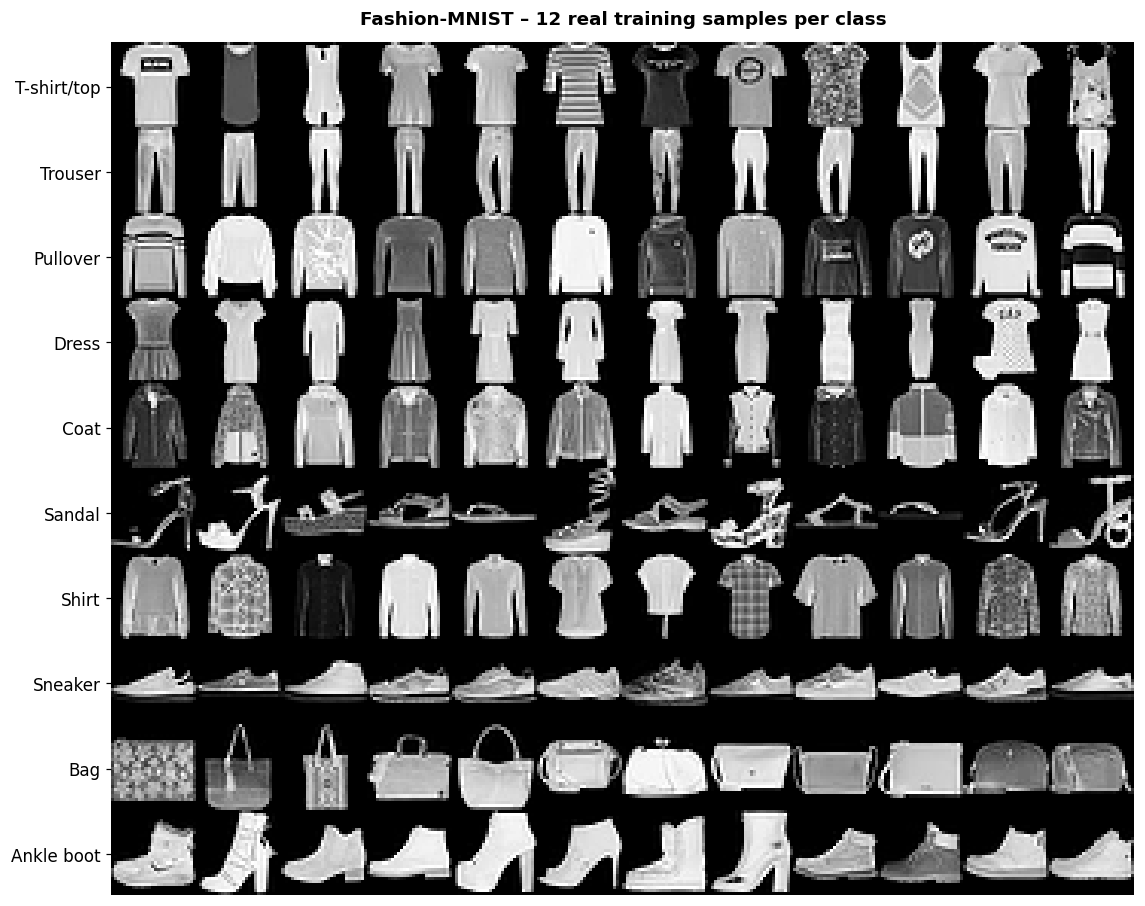

In [ ]:
raw = train_set.data.numpy(); lab = train_set.targets.numpy()
rows = [np.hstack([raw[lab == c][i] for i in range(12)]) for c in range(10)]
canvas = np.vstack(rows)

fig, ax = plt.subplots(figsize=(12, 10.5))
ax.imshow(canvas, cmap="gray")
ax.set_yticks(np.arange(10) * 28 + 14); ax.set_yticklabels(CLASS_NAMES, fontsize=11)
ax.set_xticks([]); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Fashion-MNIST – 12 real training samples per class", pad=12)
savefig("01_dataset_samples.png"); plt.show()

### 3.2 Dataset statistics

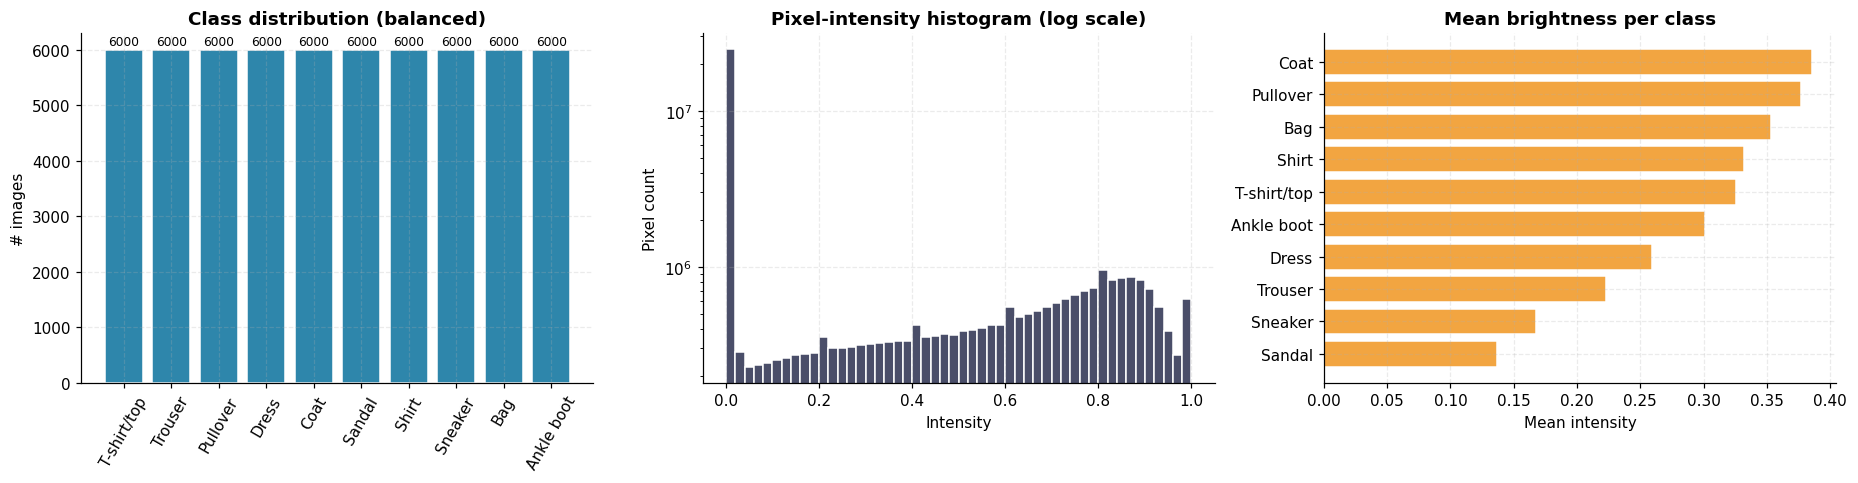

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

counts = np.bincount(lab, minlength=10)
bars = axes[0].bar(CLASS_NAMES, counts, color=PAL["real"], edgecolor="white")
axes[0].set_title("Class distribution (balanced)"); axes[0].set_ylabel("# images")
axes[0].tick_params(axis="x", rotation=60)
for b_, c_ in zip(bars, counts):
    axes[0].text(b_.get_x() + b_.get_width()/2, c_ + 80, str(c_), ha="center", fontsize=8)

axes[1].hist(raw.ravel() / 255.0, bins=50, color=PAL["neutral"], edgecolor="white")
axes[1].set_yscale("log"); axes[1].set_title("Pixel-intensity histogram (log scale)")
axes[1].set_xlabel("Intensity"); axes[1].set_ylabel("Pixel count")

mean_bright = np.array([raw[lab == c].mean() / 255.0 for c in range(10)])
order = np.argsort(mean_bright)
axes[2].barh(np.array(CLASS_NAMES)[order], mean_bright[order], color=PAL["gold"], edgecolor="white")
axes[2].set_title("Mean brightness per class"); axes[2].set_xlabel("Mean intensity")

plt.tight_layout(); savefig("02_dataset_stats.png"); plt.show()

### 3.3 Class-wise mean image

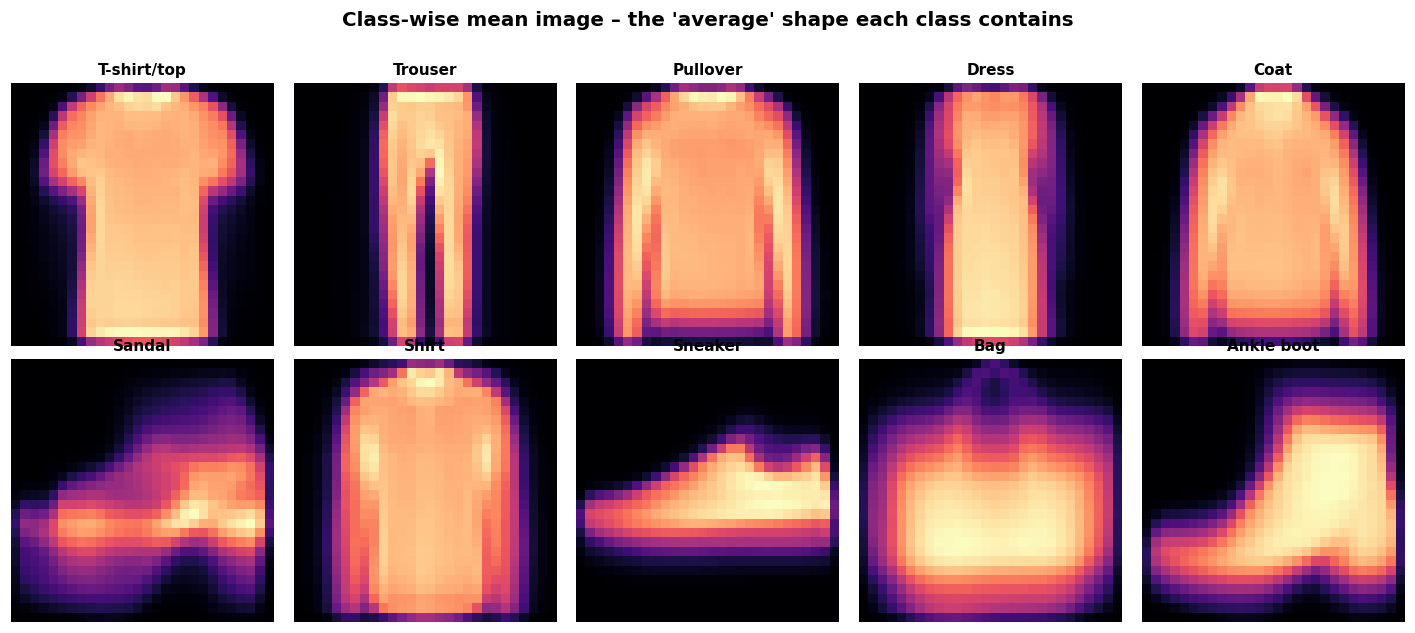

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for c, ax in enumerate(axes.flat):
    ax.imshow(raw[lab == c].mean(0), cmap="magma"); ax.set_title(CLASS_NAMES[c], fontsize=10); ax.axis("off")
fig.suptitle("Class-wise mean image – the 'average' shape each class contains", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout(); savefig("03_class_mean_images.png"); plt.show()

### 3.4 3D structure of the real data (PCA of raw pixels, interactive)

In [ ]:
rng = np.random.RandomState(CFG["SEED"])
idx = rng.choice(len(raw), 4000, replace=False)
flat = raw[idx].reshape(len(idx), -1) / 255.0
pca_raw = PCA(n_components=3, random_state=CFG["SEED"]).fit(flat)
Zr = pca_raw.transform(flat); ev = pca_raw.explained_variance_ratio_ * 100

fig = go.Figure()
for c, name in enumerate(CLASS_NAMES):
    m = lab[idx] == c
    fig.add_trace(go.Scatter3d(x=Zr[m, 0], y=Zr[m, 1], z=Zr[m, 2], mode="markers", name=name,
                               marker=dict(size=2.6, opacity=0.8)))
fig.update_layout(
    title=f"Real Fashion-MNIST in 3D PCA space (variance captured: {ev.sum():.1f}%)",
    template="plotly_white", height=680, legend=dict(itemsizing="constant"),
    scene=dict(xaxis_title=f"PC1 ({ev[0]:.1f}%)", yaxis_title=f"PC2 ({ev[1]:.1f}%)", zaxis_title=f"PC3 ({ev[2]:.1f}%)"))
fig.show()

**Reading the plot:** classes form distinct but overlapping clusters (footwear separated from upper-body garments, trousers isolated). A good generator must reproduce *all* of these regions – this plot is revisited in §9 with generated samples overlaid.

<a id="4"></a>
## 4. DCGAN Architecture

**Generator** – maps $z\in\mathbb{R}^{100}$ to a 32×32 image: `ConvTranspose(4×4)` projection → three stride-2 transposed convolutions (4→8→16→32) with BatchNorm + ReLU → Tanh.

**Discriminator** – mirror image: three stride-2 convolutions (32→16→8→4) with BatchNorm + LeakyReLU(0.2) → a 4×4 convolution producing a single logit. `BCEWithLogitsLoss` is used for numerical stability.

In [ ]:
NZ, NGF, NDF = CFG["NZ"], CFG["NGF"], CFG["NDF"]

class Generator(nn.Module):
    def __init__(self, nz=NZ, ngf=NGF, nc=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf*4, 4, 1, 0, bias=False),  nn.BatchNorm2d(ngf*4), nn.ReLU(True),   # 4x4
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf*2), nn.ReLU(True), # 8x8
            nn.ConvTranspose2d(ngf*2, ngf, 4, 2, 1, bias=False),   nn.BatchNorm2d(ngf),   nn.ReLU(True), # 16x16
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),      nn.Tanh()                             # 32x32
        )
    def forward(self, z): return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, ndf=NDF, nc=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),                                  nn.LeakyReLU(0.2, True),  # 16x16
            nn.Conv2d(ndf, ndf*2, 4, 2, 1, bias=False),   nn.BatchNorm2d(ndf*2),    nn.LeakyReLU(0.2, True),  # 8x8
            nn.Conv2d(ndf*2, ndf*4, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*4),    nn.LeakyReLU(0.2, True),  # 4x4
            nn.Conv2d(ndf*4, 1, 4, 1, 0, bias=False)                                                           # 1x1 logit
        )
    def forward(self, x): return self.net(x).view(-1)

def weights_init(m):
    cn = m.__class__.__name__
    if "Conv" in cn:
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif "BatchNorm" in cn:
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

netG = Generator().to(device); netG.apply(weights_init)
netD = Discriminator().to(device); netD.apply(weights_init)

def layer_summary(model, x):
    rows, hooks = [], []
    def hook(mod, inp, out):
        rows.append(dict(Layer=mod.__class__.__name__, Output_shape=tuple(out.shape[1:]),
                         Params=sum(p.numel() for p in mod.parameters())))
    for m in model.modules():
        if len(list(m.children())) == 0: hooks.append(m.register_forward_hook(hook))
    model.eval()
    with torch.no_grad(): model(x)
    for h in hooks: h.remove()
    model.train()
    return pd.DataFrame(rows)

print("GENERATOR"); display(layer_summary(netG, torch.randn(2, NZ, 1, 1, device=device)))
print("DISCRIMINATOR"); display(layer_summary(netD, torch.randn(2, 1, CFG['IMG'], CFG['IMG'], device=device)))

n_g = sum(p.numel() for p in netG.parameters()); n_d = sum(p.numel() for p in netD.parameters())
print(f"Generator parameters     : {n_g:,}")
print(f"Discriminator parameters : {n_d:,}")

GENERATOR


,Layer,Output_shape,Params
0,ConvTranspose2d,"(256, 4, 4)",409600
1,BatchNorm2d,"(256, 4, 4)",512
2,ReLU,"(256, 4, 4)",0
3,ConvTranspose2d,"(128, 8, 8)",524288
4,BatchNorm2d,"(128, 8, 8)",256
5,ReLU,"(128, 8, 8)",0
6,ConvTranspose2d,"(64, 16, 16)",131072
7,BatchNorm2d,"(64, 16, 16)",128
8,ReLU,"(64, 16, 16)",0
9,ConvTranspose2d,"(1, 32, 32)",1024


DISCRIMINATOR


,Layer,Output_shape,Params
0,Conv2d,"(64, 16, 16)",1024
1,LeakyReLU,"(64, 16, 16)",0
2,Conv2d,"(128, 8, 8)",131072
3,BatchNorm2d,"(128, 8, 8)",256
4,LeakyReLU,"(128, 8, 8)",0
5,Conv2d,"(256, 4, 4)",524288
6,BatchNorm2d,"(256, 4, 4)",512
7,LeakyReLU,"(256, 4, 4)",0
8,Conv2d,"(1, 1, 1)",4096


Generator parameters     : 1,066,880
Discriminator parameters : 661,248


### 4.1 Architecture diagram

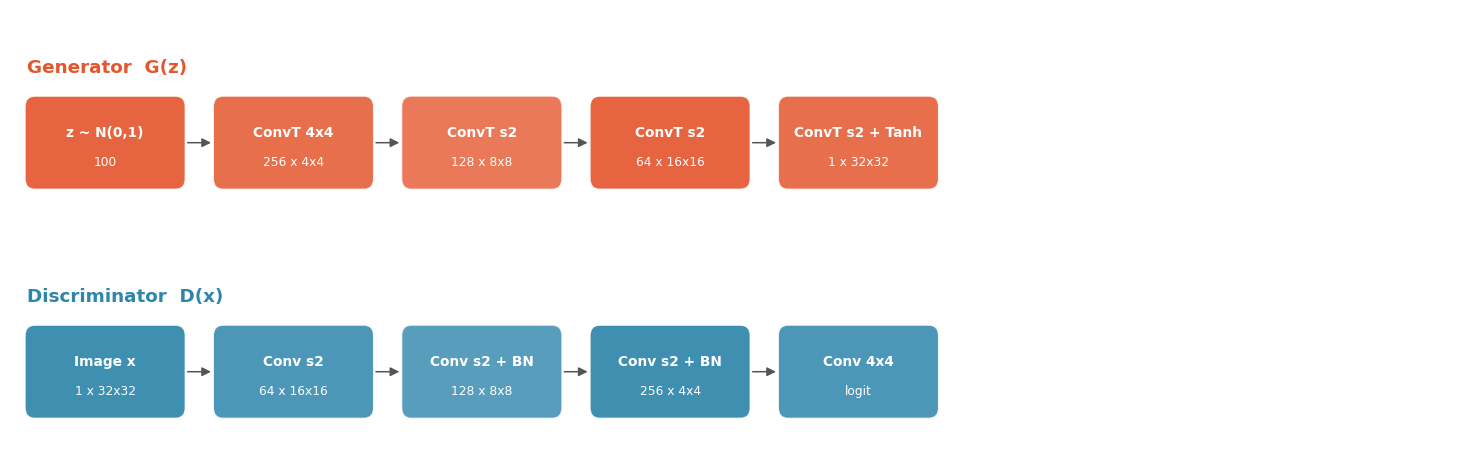

In [ ]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def draw_pipeline(ax, title, blocks, color, y=0):
    x = 0.0
    for i, (name, sub) in enumerate(blocks):
        w = 1.9
        ax.add_patch(FancyBboxPatch((x, y), w, 1.0, boxstyle="round,pad=0.03,rounding_size=0.12",
                                    fc=color, ec="white", alpha=0.92 - 0.06 * (i % 3)))
        ax.text(x + w/2, y + 0.62, name, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        ax.text(x + w/2, y + 0.28, sub,  ha="center", va="center", color="white", fontsize=8)
        if i < len(blocks) - 1:
            ax.add_patch(FancyArrowPatch((x + w + 0.02, y + 0.5), (x + w + 0.38, y + 0.5), arrowstyle="-|>", mutation_scale=12, color="#555"))
        x += w + 0.4
    ax.text(0, y + 1.3, title, fontsize=12, fontweight="bold", color=color)

fig, ax = plt.subplots(figsize=(17, 5.2)); ax.axis("off"); ax.set_xlim(-0.2, 17.5); ax.set_ylim(-0.4, 4.6)
draw_pipeline(ax, "Generator  G(z)", [("z ~ N(0,1)", "100"), ("ConvT 4x4", "256 x 4x4"), ("ConvT s2", "128 x 8x8"),
                                      ("ConvT s2", "64 x 16x16"), ("ConvT s2 + Tanh", "1 x 32x32")], PAL["g"], y=2.6)
draw_pipeline(ax, "Discriminator  D(x)", [("Image x", "1 x 32x32"), ("Conv s2", "64 x 16x16"), ("Conv s2 + BN", "128 x 8x8"),
                                          ("Conv s2 + BN", "256 x 4x4"), ("Conv 4x4", "logit")], PAL["d"], y=0.0)
savefig("04_architecture.png"); plt.show()

<a id="5"></a>
## 5. Evaluation Toolkit

The Inception network used by the standard FID is trained on ImageNet colour photos and is a poor feature extractor for 32×32 grayscale clothing. Instead, a small CNN classifier is trained on real Fashion-MNIST (a few seconds on GPU), and its 128-dimensional penultimate layer is used as the feature space. The **Fréchet Distance (FD)** between Gaussians fitted to real and generated features is then computed:

$$FD = \lVert \mu_r-\mu_g\rVert^2 + \mathrm{Tr}\!\left(\Sigma_r+\Sigma_g-2(\Sigma_r\Sigma_g)^{1/2}\right)$$

*Lower is better.* A "real-vs-real" floor (train subset vs test set) is also computed as the best achievable value. The same classifier provides class predictions for generated images (diversity / mode-collapse analysis).

In [ ]:
class FMNISTNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(True), nn.MaxPool2d(2))
        self.fc = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(True))
        self.head = nn.Linear(128, 10)
    def forward(self, x):
        f = self.fc(self.conv(x)); return self.head(f), f

clf = FMNISTNet().to(device)
opt_c = torch.optim.Adam(clf.parameters(), lr=1e-3)
for ep in range(4):
    perm = torch.randperm(len(X_train), device=device)
    for i in range(0, len(perm), 256):
        b = perm[i:i+256]
        loss = F.cross_entropy(clf(X_train[b])[0], y_train[b])
        opt_c.zero_grad(); loss.backward(); opt_c.step()
clf.eval()
for p in clf.parameters(): p.requires_grad_(False)

@torch.no_grad()
def extract(x, bs=1000):
    L, Fe = [], []
    for i in range(0, len(x), bs):
        lo, fe = clf(x[i:i+bs]); L.append(lo); Fe.append(fe)
    return torch.cat(L), torch.cat(Fe)

logits_test, feat_test = extract(X_test)
clf_acc = (logits_test.argmax(1) == y_test).float().mean().item() * 100
print(f"Feature-extractor classifier test accuracy: {clf_acc:.2f}%")

def frechet(f1, f2, eps=1e-6):
    f1 = f1.double().cpu().numpy(); f2 = f2.double().cpu().numpy()
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1 = np.cov(f1, rowvar=False) + eps * np.eye(f1.shape[1])
    s2 = np.cov(f2, rowvar=False) + eps * np.eye(f2.shape[1])
    covmean = sqrtm(s1 @ s2)
    if np.iscomplexobj(covmean): covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

@torch.no_grad()
def generate(n, bs=1000, z=None):
    # BatchNorm stays in train mode (batch statistics) – the standard behaviour for DCGAN sampling
    if z is not None: return netG(z)
    return torch.cat([netG(torch.randn(min(bs, n - i), NZ, 1, 1, device=device)) for i in range(0, n, bs)])

def fd_now(n=5000):
    return frechet(feat_test, extract(generate(n))[1])

# Real-vs-real reference floor
ridx = torch.randperm(len(X_train), device=device)[:10000]
FD_FLOOR = frechet(feat_test, extract(X_train[ridx])[1])
print(f"Real-vs-real Frechet floor (train subset vs test): {FD_FLOOR:.3f}")

Feature-extractor classifier test accuracy: 90.20%
Real-vs-real Frechet floor (train subset vs test): 0.271


<a id="6"></a>
## 6. Adversarial Training

Each iteration performs:
1. **Discriminator step** – maximise $\log D(x) + \log(1-D(G(z)))$ on a real batch (label 0.9) and a fake batch (label 0)
2. **Generator step** – minimise $-\log D(G(z))$ (non-saturating loss)

Tracked every iteration: $L_G$, $L_D$, $D(x)$, $D(G(z))$. Tracked every epoch: fixed-noise snapshot, Discriminator score distributions on 1,000 real / 1,000 fake images (used for the 3D plot in §9), and Fréchet Distance every `FD_EVERY` epochs.

In [ ]:
E, B, N = CFG["EPOCHS"], CFG["BATCH"], len(X_train)
iters = N // B

criterion = nn.BCEWithLogitsLoss()
optG = torch.optim.Adam(netG.parameters(), lr=CFG["LR"], betas=(CFG["BETA1"], 0.999))
optD = torch.optim.Adam(netD.parameters(), lr=CFG["LR"], betas=(CFG["BETA1"], 0.999))

fixed_noise = torch.randn(64, NZ, 1, 1, device=device)
eval_real = X_test[:1000]

hist = dict(g_iter=[], d_iter=[], dx_iter=[], dgz_iter=[],
            g_ep=[], d_ep=[], dx_ep=[], dgz_ep=[], fd_ep=[], fd_val=[], time=[])
snapshots, score_real, score_fake = {}, [], []

@torch.no_grad()
def record_epoch_state(ep):
    snapshots[ep] = netG(fixed_noise).cpu()
    score_real.append(torch.sigmoid(netD(eval_real)).cpu().numpy())
    score_fake.append(torch.sigmoid(netD(generate(1000))).cpu().numpy())

# ---- Epoch 0 = untrained baseline ----
record_epoch_state(0)
hist["fd_ep"].append(0); hist["fd_val"].append(fd_now())
print(f"Baseline (untrained) Frechet distance: {hist['fd_val'][0]:.2f}")

t_start = time.time()
for epoch in range(1, E + 1):
    t0 = time.time()
    perm = torch.randperm(N, device=device)
    gl, dl, dxl, dgl = [], [], [], []
    for it in tqdm(range(iters), desc=f"Epoch {epoch:02d}/{E}", leave=False):
        real = X_train[perm[it*B:(it+1)*B]]; b = real.size(0)

        # ---------------- Discriminator update ----------------
        netD.zero_grad(set_to_none=True)
        out_real = netD(real)
        loss_real = criterion(out_real, torch.full_like(out_real, CFG["LABEL_REAL"]))
        fake = netG(torch.randn(b, NZ, 1, 1, device=device))
        out_fake = netD(fake.detach())
        loss_fake = criterion(out_fake, torch.zeros_like(out_fake))
        lossD = loss_real + loss_fake
        lossD.backward(); optD.step()

        # ---------------- Generator update --------------------
        netG.zero_grad(set_to_none=True)
        out_g = netD(fake)
        lossG = criterion(out_g, torch.ones_like(out_g))
        lossG.backward(); optG.step()

        gl.append(lossG.detach()); dl.append(lossD.detach())
        dxl.append(torch.sigmoid(out_real).mean().detach()); dgl.append(torch.sigmoid(out_fake).mean().detach())

    gl, dl, dxl, dgl = [torch.stack(v).cpu().numpy() for v in (gl, dl, dxl, dgl)]
    hist["g_iter"] += gl.tolist(); hist["d_iter"] += dl.tolist()
    hist["dx_iter"] += dxl.tolist(); hist["dgz_iter"] += dgl.tolist()
    hist["g_ep"].append(gl.mean()); hist["d_ep"].append(dl.mean())
    hist["dx_ep"].append(dxl.mean()); hist["dgz_ep"].append(dgl.mean())

    record_epoch_state(epoch)
    msg = ""
    if epoch % CFG["FD_EVERY"] == 0 or epoch == E:
        fd = fd_now(); hist["fd_ep"].append(epoch); hist["fd_val"].append(fd); msg = f" | FD {fd:7.2f}"
    hist["time"].append(time.time() - t0)
    print(f"Epoch {epoch:02d}/{E} | L_D {hist['d_ep'][-1]:.3f} | L_G {hist['g_ep'][-1]:.3f} | "
          f"D(x) {hist['dx_ep'][-1]:.3f} | D(G(z)) {hist['dgz_ep'][-1]:.3f}{msg} | {hist['time'][-1]:.1f}s")

TRAIN_TIME = time.time() - t_start
print(f"\nTraining finished in {TRAIN_TIME/60:.1f} min")

torch.save(netG.state_dict(), os.path.join(OUT_DIR, "generator.pth"))
torch.save(netD.state_dict(), os.path.join(OUT_DIR, "discriminator.pth"))

Baseline (untrained) Frechet distance: 935.43


Epoch 01/30:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch 01/30 | L_D 0.608 | L_G 3.112 | D(x) 0.776 | D(G(z)) 0.127 | 12.1s


Epoch 02/30:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch 02/30 | L_D 0.791 | L_G 2.230 | D(x) 0.695 | D(G(z)) 0.205 | 11.5s


...

Epoch 28/30 | L_D 0.447 | L_G 4.334 | D(x) 0.858 | D(G(z)) 0.042 | 12.5s


Epoch 29/30:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch 29/30 | L_D 0.437 | L_G 4.352 | D(x) 0.861 | D(G(z)) 0.039 | 12.5s


Epoch 30/30:   0%|          | 0/468 [00:00<?, ?it/s]

Epoch 30/30 | L_D 0.459 | L_G 4.171 | D(x) 0.853 | D(G(z)) 0.047 | FD    7.62 | 12.7s

Training finished in 6.2 min


<a id="7"></a>
## 7. Loss Curve Analysis

### 7.1 Generator & Discriminator loss dashboard

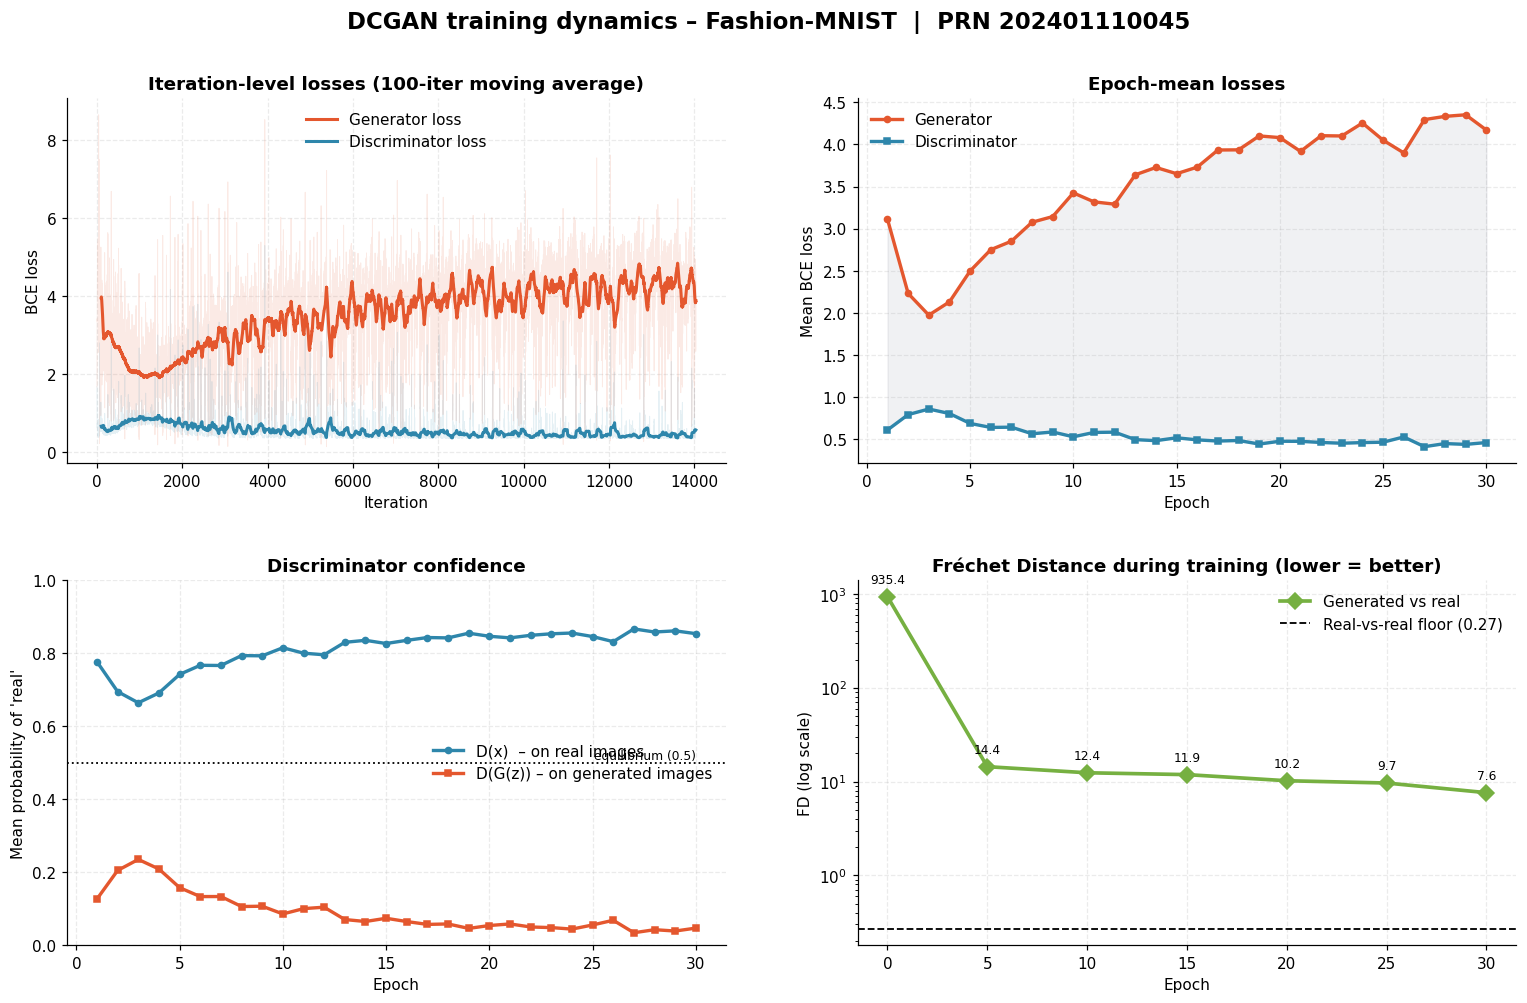

In [ ]:
def smooth(x, w):
    x = np.asarray(x); w = min(w, len(x))
    return np.convolve(x, np.ones(w) / w, mode="valid")

ep_axis = np.arange(1, E + 1)
g_it, d_it = np.array(hist["g_iter"]), np.array(hist["d_iter"])
W = 100

fig = plt.figure(figsize=(17, 10)); gs = GridSpec(2, 2, figure=fig, hspace=0.32, wspace=0.2)

ax = fig.add_subplot(gs[0, 0])
ax.plot(g_it, color=PAL["g"], alpha=0.12, lw=0.6); ax.plot(d_it, color=PAL["d"], alpha=0.12, lw=0.6)
ax.plot(np.arange(W - 1, len(g_it)), smooth(g_it, W), color=PAL["g"], lw=2, label="Generator loss")
ax.plot(np.arange(W - 1, len(d_it)), smooth(d_it, W), color=PAL["d"], lw=2, label="Discriminator loss")
ax.set_title(f"Iteration-level losses ({W}-iter moving average)"); ax.set_xlabel("Iteration"); ax.set_ylabel("BCE loss"); ax.legend()

ax = fig.add_subplot(gs[0, 1])
ax.plot(ep_axis, hist["g_ep"], "-o", color=PAL["g"], lw=2.2, ms=4, label="Generator")
ax.plot(ep_axis, hist["d_ep"], "-s", color=PAL["d"], lw=2.2, ms=4, label="Discriminator")
ax.fill_between(ep_axis, hist["g_ep"], hist["d_ep"], color=PAL["neutral"], alpha=0.08)
ax.set_title("Epoch-mean losses"); ax.set_xlabel("Epoch"); ax.set_ylabel("Mean BCE loss"); ax.legend()

ax = fig.add_subplot(gs[1, 0])
ax.plot(ep_axis, hist["dx_ep"], "-o", color=PAL["real"], lw=2.2, ms=4, label="D(x)  – on real images")
ax.plot(ep_axis, hist["dgz_ep"], "-s", color=PAL["fake"], lw=2.2, ms=4, label="D(G(z)) – on generated images")
ax.axhline(0.5, color="k", ls=":", lw=1.2); ax.text(E, 0.51, "equilibrium (0.5)", ha="right", fontsize=8)
ax.set_ylim(0, 1); ax.set_title("Discriminator confidence"); ax.set_xlabel("Epoch"); ax.set_ylabel("Mean probability of 'real'"); ax.legend(loc="center right")

ax = fig.add_subplot(gs[1, 1])
ax.plot(hist["fd_ep"], hist["fd_val"], "-D", color=PAL["accent"], lw=2.4, ms=7, label="Generated vs real")
ax.axhline(FD_FLOOR, color="k", ls="--", lw=1.2, label=f"Real-vs-real floor ({FD_FLOOR:.2f})")
ax.set_yscale("log"); ax.set_title("Fréchet Distance during training (lower = better)")
ax.set_xlabel("Epoch"); ax.set_ylabel("FD (log scale)"); ax.legend()
for x_, y_ in zip(hist["fd_ep"], hist["fd_val"]): ax.annotate(f"{y_:.1f}", (x_, y_), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8)

fig.suptitle(f"DCGAN training dynamics – Fashion-MNIST  |  PRN {CFG['PRN']}", fontsize=15, fontweight="bold", y=0.96)
savefig("05_loss_dashboard.png"); plt.show()

### 7.2 Interactive loss explorer

In [ ]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Epoch-mean losses", "Discriminator output on real vs generated"))
fig.add_trace(go.Scatter(x=ep_axis, y=hist["g_ep"], name="Generator loss", mode="lines+markers", line=dict(color=PAL["g"], width=3)), 1, 1)
fig.add_trace(go.Scatter(x=ep_axis, y=hist["d_ep"], name="Discriminator loss", mode="lines+markers", line=dict(color=PAL["d"], width=3)), 1, 1)
fig.add_trace(go.Scatter(x=ep_axis, y=hist["dx_ep"], name="D(x)", mode="lines+markers", line=dict(color=PAL["real"], width=3)), 1, 2)
fig.add_trace(go.Scatter(x=ep_axis, y=hist["dgz_ep"], name="D(G(z))", mode="lines+markers", line=dict(color=PAL["fake"], width=3)), 1, 2)
fig.add_hline(y=0.5, line_dash="dot", line_color="gray", row=1, col=2)
fig.update_xaxes(title_text="Epoch"); fig.update_yaxes(title_text="Loss", row=1, col=1); fig.update_yaxes(title_text="Probability", range=[0, 1], row=1, col=2)
fig.update_layout(template="plotly_white", height=470, hovermode="x unified", legend=dict(orientation="h", y=-0.2))
fig.show()

### 7.3 3D training trajectory (D loss × G loss × epoch)

In [ ]:
fig = go.Figure()
fig.add_trace(go.Scatter3d(
    x=hist["d_ep"], y=hist["g_ep"], z=ep_axis, mode="lines+markers",
    line=dict(color="rgba(80,80,80,0.5)", width=4),
    marker=dict(size=5, color=ep_axis, colorscale="Turbo", colorbar=dict(title="Epoch", len=0.6), line=dict(width=0.5, color="white")),
    text=[f"Epoch {e}" for e in ep_axis], hovertemplate="%{text}<br>D loss %{x:.3f}<br>G loss %{y:.3f}<extra></extra>"))
fig.add_trace(go.Scatter3d(x=[hist["d_ep"][0]], y=[hist["g_ep"][0]], z=[1], mode="markers+text", text=["start"], textposition="top center",
                           marker=dict(size=9, color="green"), showlegend=False))
fig.add_trace(go.Scatter3d(x=[hist["d_ep"][-1]], y=[hist["g_ep"][-1]], z=[E], mode="markers+text", text=["end"], textposition="top center",
                           marker=dict(size=9, color="crimson"), showlegend=False))
fig.update_layout(title="Training trajectory in (L_D, L_G, epoch) space", template="plotly_white", height=680, showlegend=False,
                  scene=dict(xaxis_title="Discriminator loss", yaxis_title="Generator loss", zaxis_title="Epoch",
                             camera=dict(eye=dict(x=1.7, y=-1.7, z=0.9))))
fig.show()

### 7.4 How to interpret the loss curves
* **Healthy adversarial training** does *not* show monotonically decreasing losses. $L_D$ typically settles around 0.9–1.4 (with label smoothing 0.9) while $L_G$ settles to a plateau and fluctuates mildly – both networks keep improving against each other.
* **$D(x)$ and $D(G(z))$** should approach each other: $D(x)$ near 0.6–0.9 (smoothed target is 0.9) and $D(G(z))$ moving up from ≈0 toward 0.2–0.5. $D(G(z)) \to 0$ with exploding $L_G$ signals a *dominant discriminator* (generator receives vanishing information); $L_D \to 0$ signals discriminator victory / training collapse.
* **Fréchet Distance** is the objective check – loss values alone cannot tell image quality, but a steadily falling FD towards the real-vs-real floor confirms that the generated distribution is converging to the real one.
* The 3D trajectory shows whether the two losses spiral into a bounded region (stable game) or diverge.

Numerical conclusions drawn from *your* run are produced automatically in §11.

<a id="8"></a>
## 8. Generated Image Quality Analysis

### 8.1 Evolution of generated images (fixed noise vector)

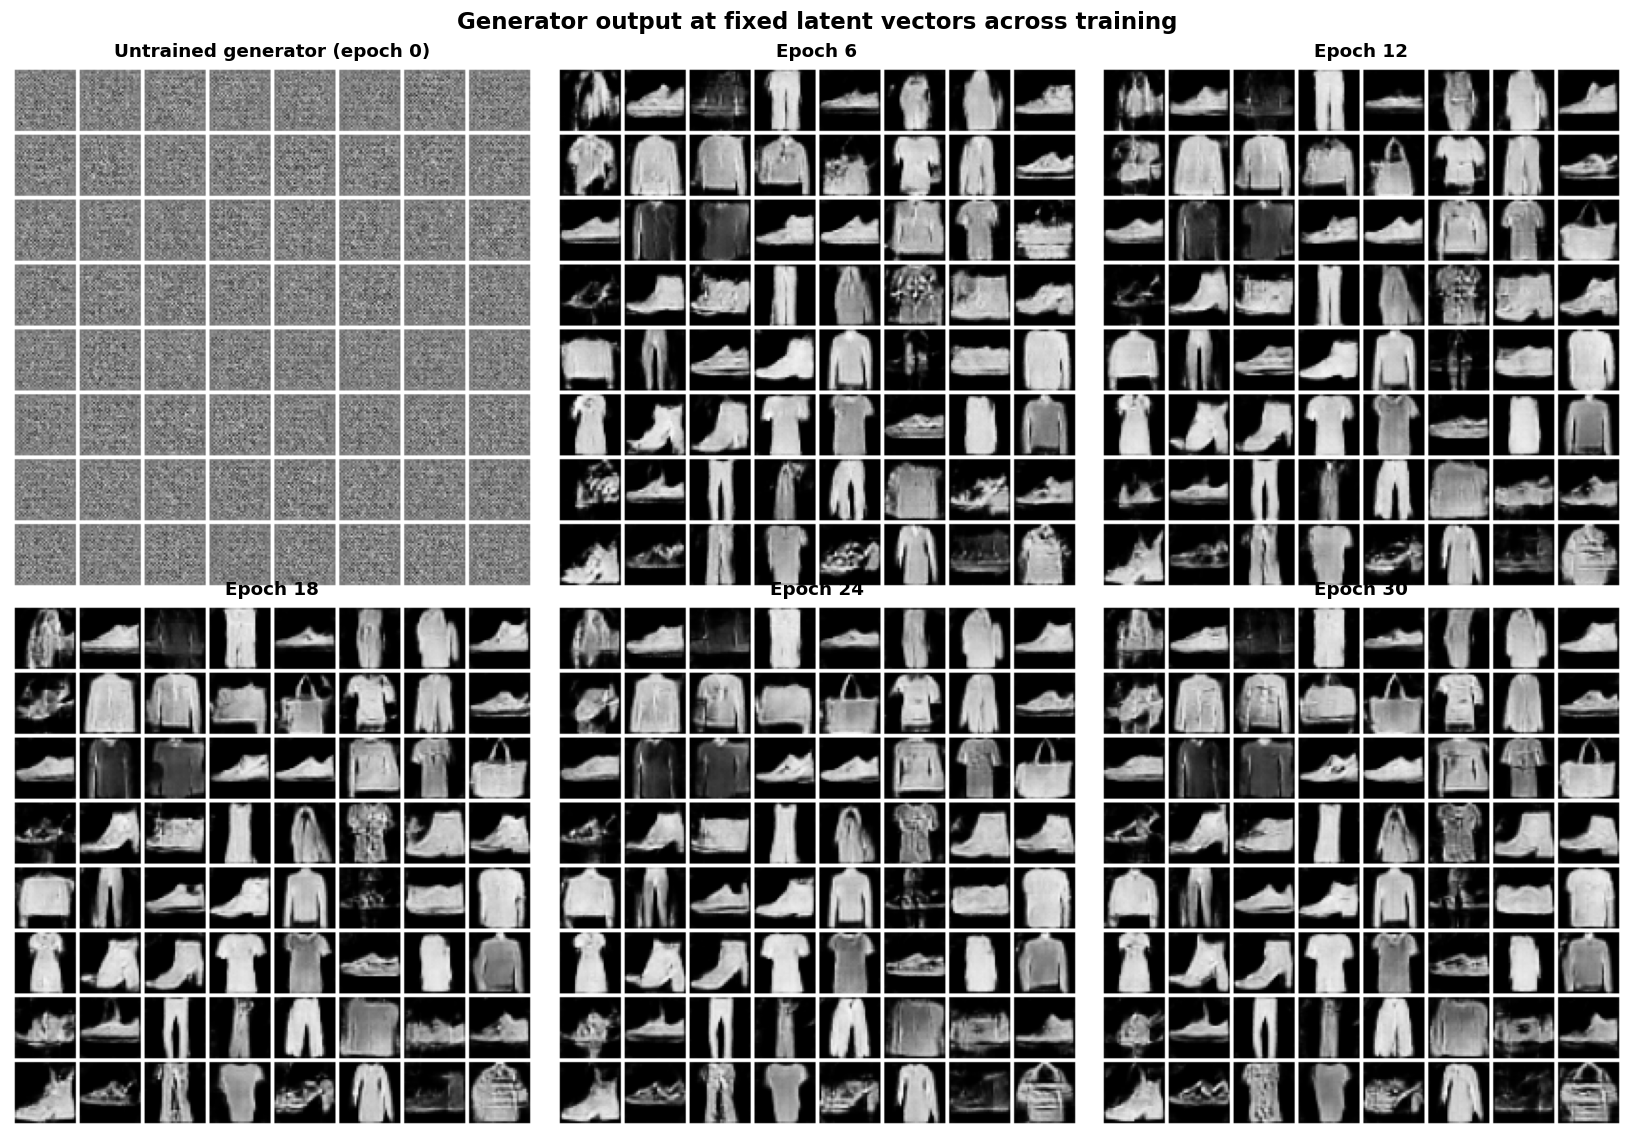

In [ ]:
show_eps = sorted(set(np.linspace(0, E, 6).astype(int).tolist()))
fig, axes = plt.subplots(2, 3, figsize=(15, 10.4))
for ax, e in zip(axes.flat, show_eps):
    ax.imshow(grid_np(snapshots[e], 8, padding=2)); ax.axis("off")
    ax.set_title(("Untrained generator (epoch 0)" if e == 0 else f"Epoch {e}"), fontsize=12)
for ax in list(axes.flat)[len(show_eps):]: ax.axis("off")
fig.suptitle("Generator output at fixed latent vectors across training", fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout(); savefig("06_training_progression.png"); plt.show()

### 8.3 Final generated samples

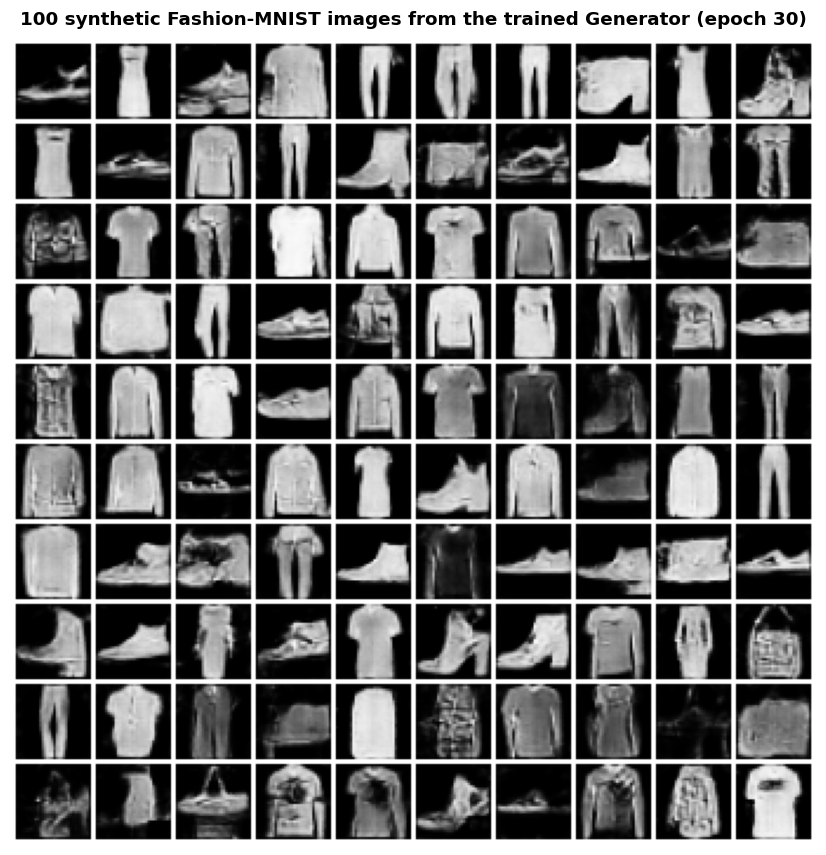

In [ ]:
torch.manual_seed(CFG["SEED"] + 1)
final_samples = generate(100)
fig, ax = plt.subplots(figsize=(9.5, 9.5))
ax.imshow(grid_np(final_samples, 10, padding=2)); ax.axis("off")
ax.set_title(f"100 synthetic Fashion-MNIST images from the trained Generator (epoch {E})", pad=10)
savefig("07_final_samples.png"); plt.show()

### 8.4 Real vs generated – side-by-side

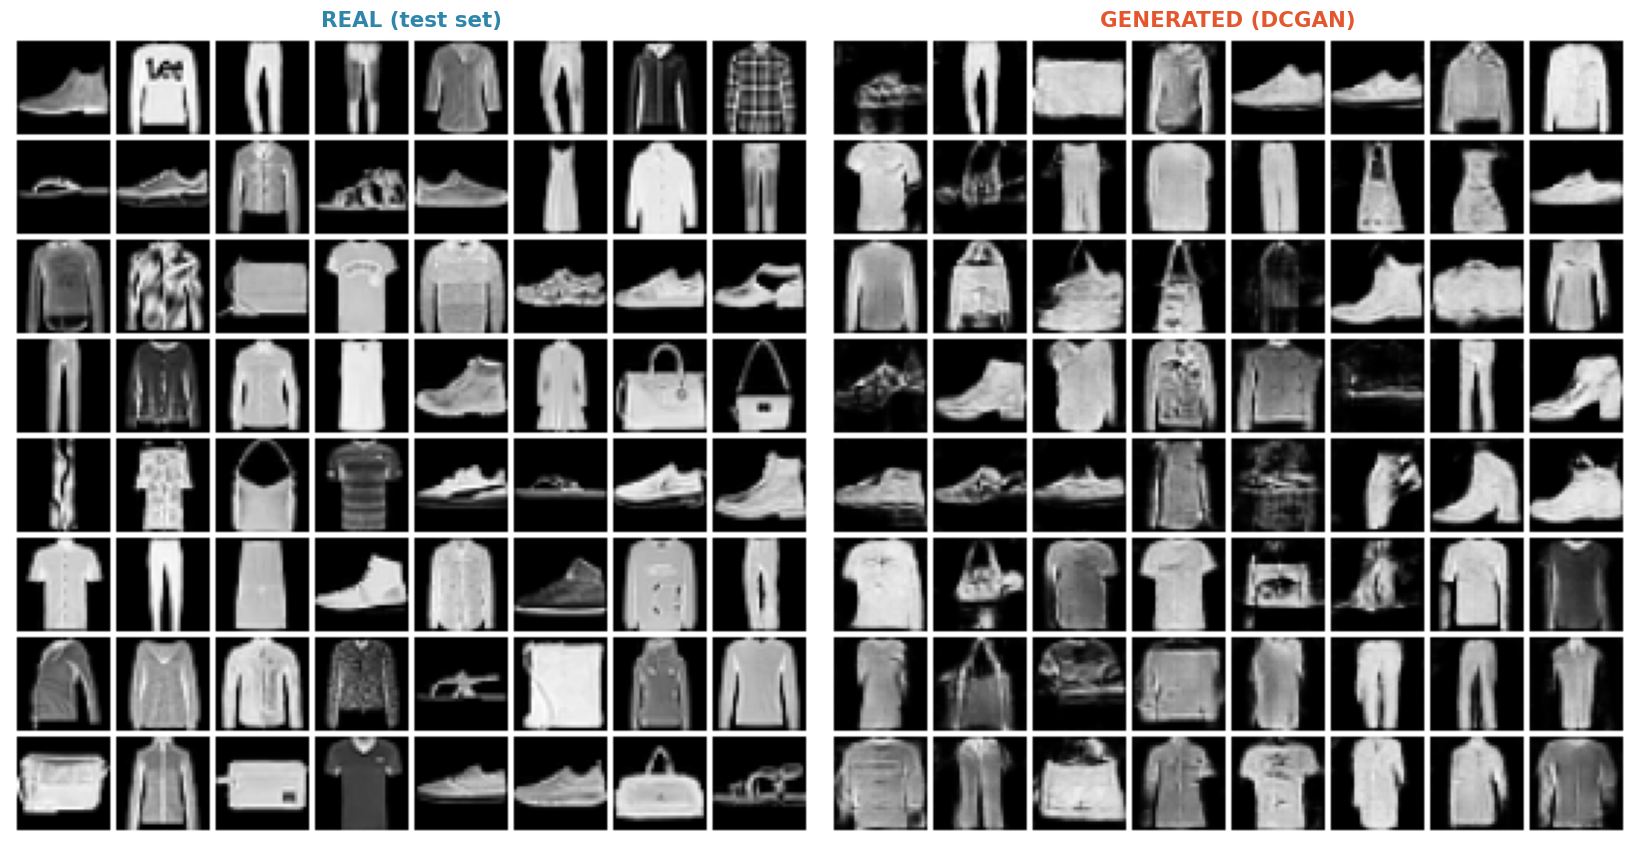

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.6))
axes[0].imshow(grid_np(X_test[:64], 8, padding=2)); axes[0].set_title("REAL (test set)", color=PAL["real"], fontsize=14)
axes[1].imshow(grid_np(generate(64), 8, padding=2)); axes[1].set_title("GENERATED (DCGAN)", color=PAL["fake"], fontsize=14)
for a in axes: a.axis("off")
plt.tight_layout(); savefig("08_real_vs_generated.png"); plt.show()

### 8.5 Pixel-level statistical comparison (10,000 real vs 10,000 generated)

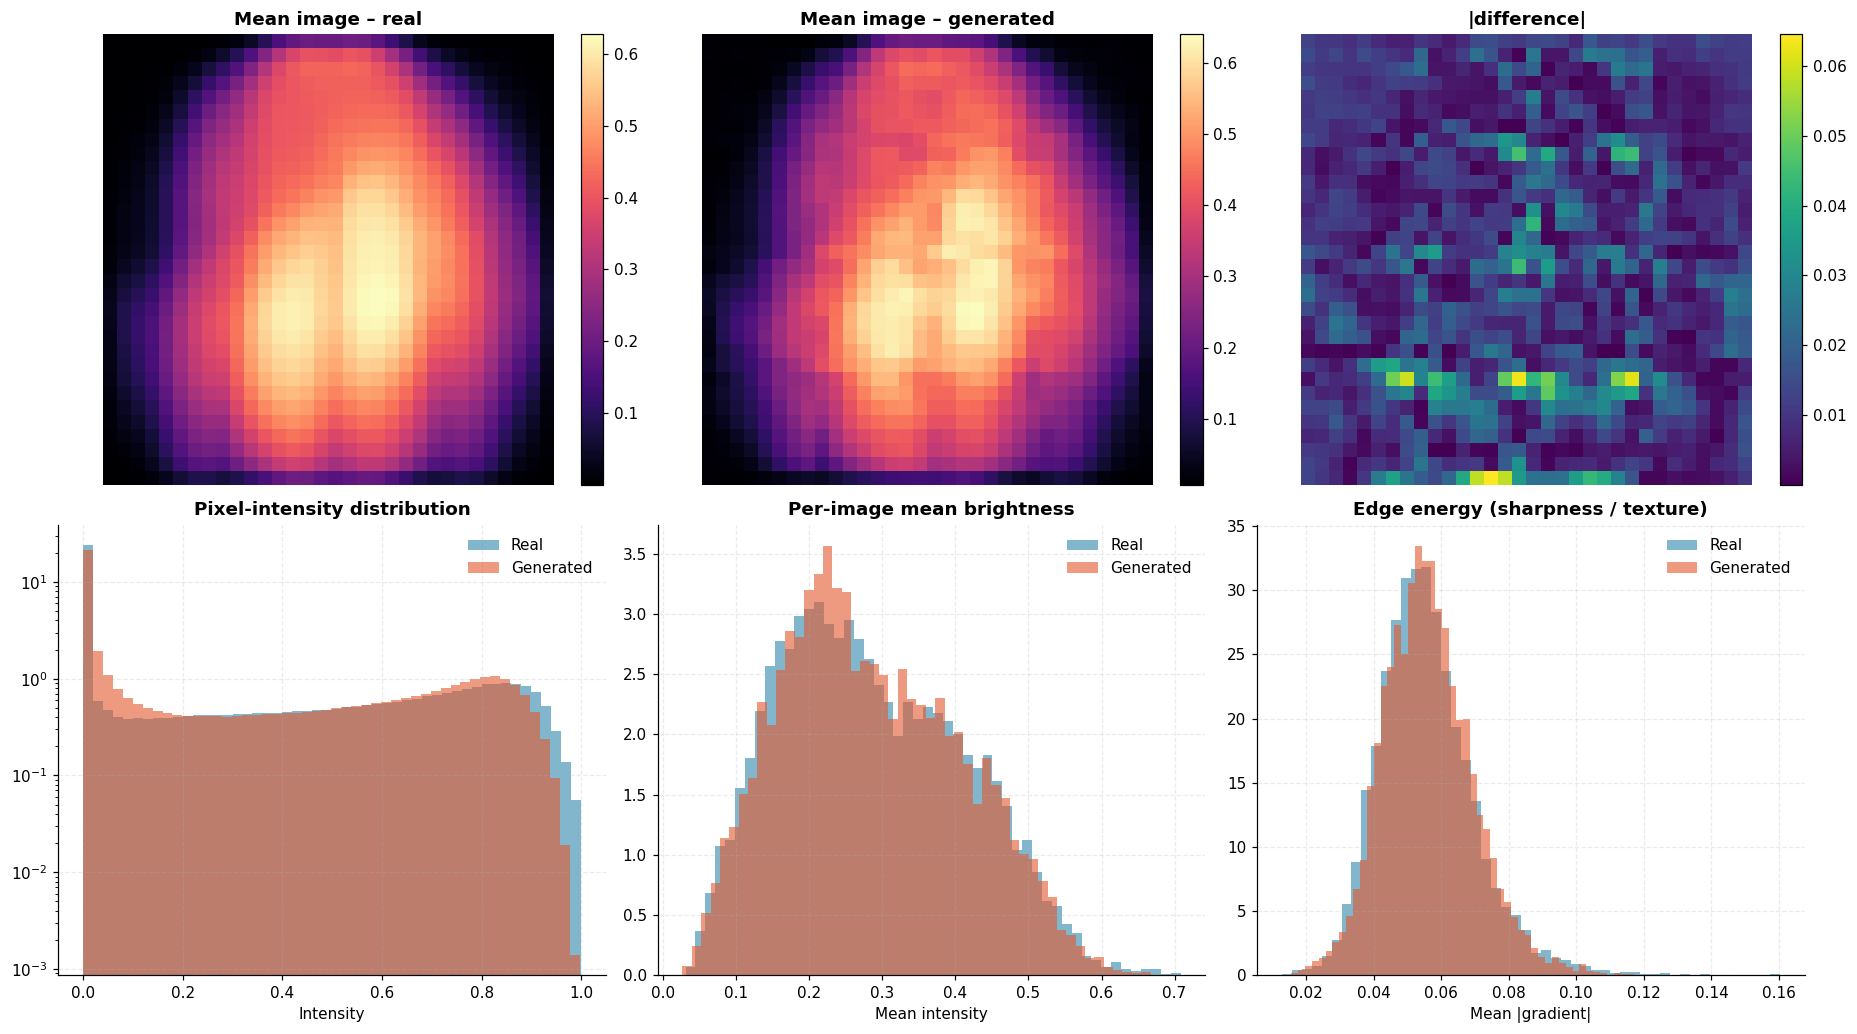

In [ ]:
real_imgs = X_test                        # 10,000 real test images
fake_imgs = generate(10000)               # 10,000 generated images
r01, f01 = (real_imgs + 1) / 2, (fake_imgs + 1) / 2

def edge_energy(x):   # mean absolute spatial gradient: proxy for sharpness / texture content
    gx = (x[:, :, :, 1:] - x[:, :, :, :-1]).abs().mean((1, 2, 3)); gy = (x[:, :, 1:, :] - x[:, :, :-1, :]).abs().mean((1, 2, 3))
    return ((gx + gy) / 2).cpu().numpy()

fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
mr, mf = r01.mean(0)[0].cpu().numpy(), f01.mean(0)[0].cpu().numpy()
for ax, img, t, cm in zip(axes[0], [mr, mf, np.abs(mr - mf)], ["Mean image – real", "Mean image – generated", "|difference|"], ["magma", "magma", "viridis"]):
    im_ = ax.imshow(img, cmap=cm); ax.set_title(t); ax.axis("off"); plt.colorbar(im_, ax=ax, fraction=0.046)

axes[1, 0].hist(r01.flatten().cpu().numpy(), bins=50, alpha=0.6, color=PAL["real"], label="Real", density=True)
axes[1, 0].hist(f01.flatten().cpu().numpy(), bins=50, alpha=0.6, color=PAL["fake"], label="Generated", density=True)
axes[1, 0].set_yscale("log"); axes[1, 0].set_title("Pixel-intensity distribution"); axes[1, 0].set_xlabel("Intensity"); axes[1, 0].legend()

axes[1, 1].hist(r01.mean((1, 2, 3)).cpu().numpy(), bins=50, alpha=0.6, color=PAL["real"], label="Real", density=True)
axes[1, 1].hist(f01.mean((1, 2, 3)).cpu().numpy(), bins=50, alpha=0.6, color=PAL["fake"], label="Generated", density=True)
axes[1, 1].set_title("Per-image mean brightness"); axes[1, 1].set_xlabel("Mean intensity"); axes[1, 1].legend()

axes[1, 2].hist(edge_energy(r01), bins=50, alpha=0.6, color=PAL["real"], label="Real", density=True)
axes[1, 2].hist(edge_energy(f01), bins=50, alpha=0.6, color=PAL["fake"], label="Generated", density=True)
axes[1, 2].set_title("Edge energy (sharpness / texture)"); axes[1, 2].set_xlabel("Mean |gradient|"); axes[1, 2].legend()
plt.tight_layout(); savefig("09_pixel_statistics.png"); plt.show()

### 8.6 Class-level diversity check using the trained classifier

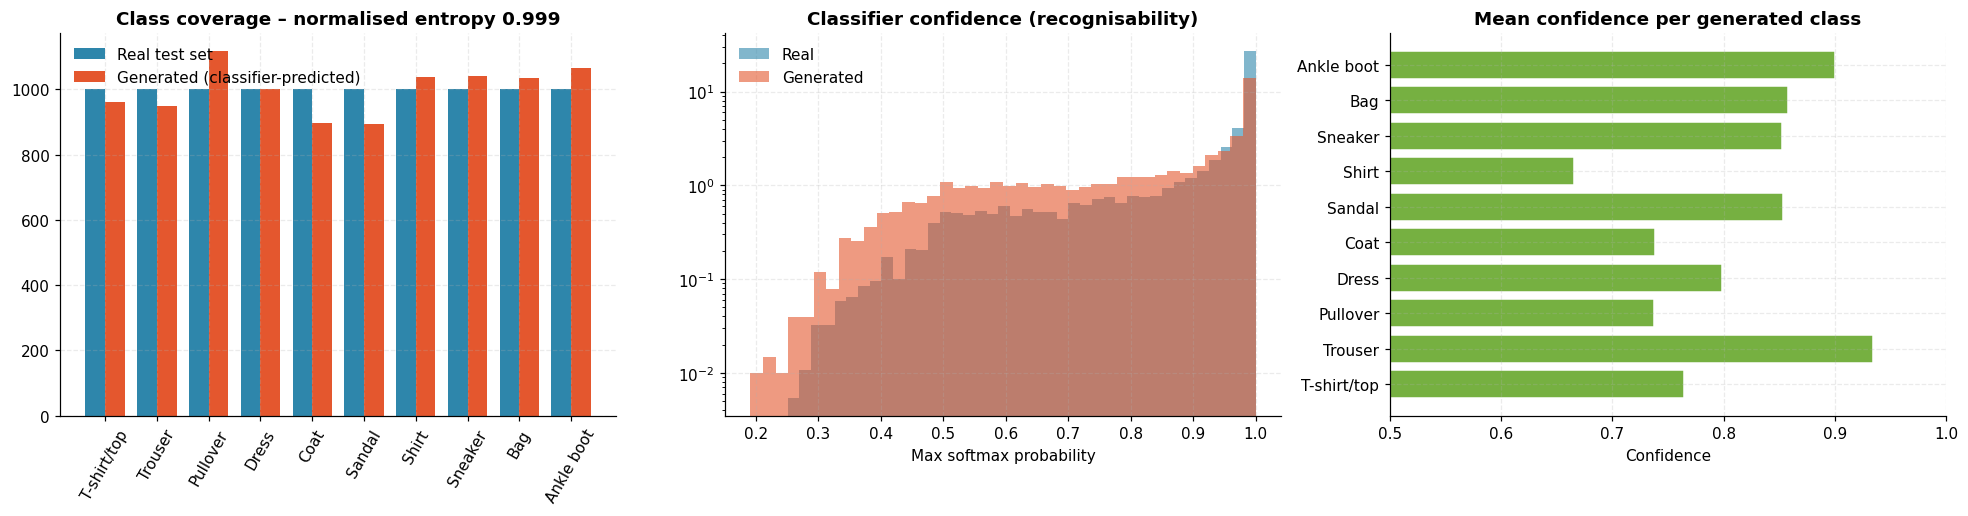

Normalised class entropy : 0.999  (1.0 = all classes equally generated)
Mean confidence          : real 0.900  |  generated 0.810


In [ ]:
logits_fake, feat_fake = extract(fake_imgs)
prob_fake = F.softmax(logits_fake, 1); conf_fake, pred_fake = prob_fake.max(1)
prob_real = F.softmax(logits_test, 1);  conf_real = prob_real.max(1)[0]

gen_counts = torch.bincount(pred_fake, minlength=10).cpu().numpy()
real_counts = np.bincount(y_test.cpu().numpy(), minlength=10)
p = gen_counts / gen_counts.sum()
class_entropy = float(-(p[p > 0] * np.log(p[p > 0])).sum() / np.log(10))   # 1.0 = perfectly uniform

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
x = np.arange(10); w = 0.38
axes[0].bar(x - w/2, real_counts, w, color=PAL["real"], label="Real test set")
axes[0].bar(x + w/2, gen_counts, w, color=PAL["fake"], label="Generated (classifier-predicted)")
axes[0].set_xticks(x); axes[0].set_xticklabels(CLASS_NAMES, rotation=60); axes[0].set_title(f"Class coverage – normalised entropy {class_entropy:.3f}"); axes[0].legend()

axes[1].hist(conf_real.cpu().numpy(), bins=40, alpha=0.6, color=PAL["real"], label="Real", density=True)
axes[1].hist(conf_fake.cpu().numpy(), bins=40, alpha=0.6, color=PAL["fake"], label="Generated", density=True)
axes[1].set_title("Classifier confidence (recognisability)"); axes[1].set_xlabel("Max softmax probability"); axes[1].legend(); axes[1].set_yscale("log")

mean_conf = [conf_fake[pred_fake == c].mean().item() if (pred_fake == c).any() else 0 for c in range(10)]
axes[2].barh(CLASS_NAMES, mean_conf, color=PAL["accent"], edgecolor="white")
axes[2].set_xlim(0.5, 1.0); axes[2].set_title("Mean confidence per generated class"); axes[2].set_xlabel("Confidence")
plt.tight_layout(); savefig("10_class_diversity.png"); plt.show()
print(f"Normalised class entropy : {class_entropy:.3f}  (1.0 = all classes equally generated)")
print(f"Mean confidence          : real {conf_real.mean():.3f}  |  generated {conf_fake.mean():.3f}")

### 8.7 Memorisation check – nearest real training image to each generated sample

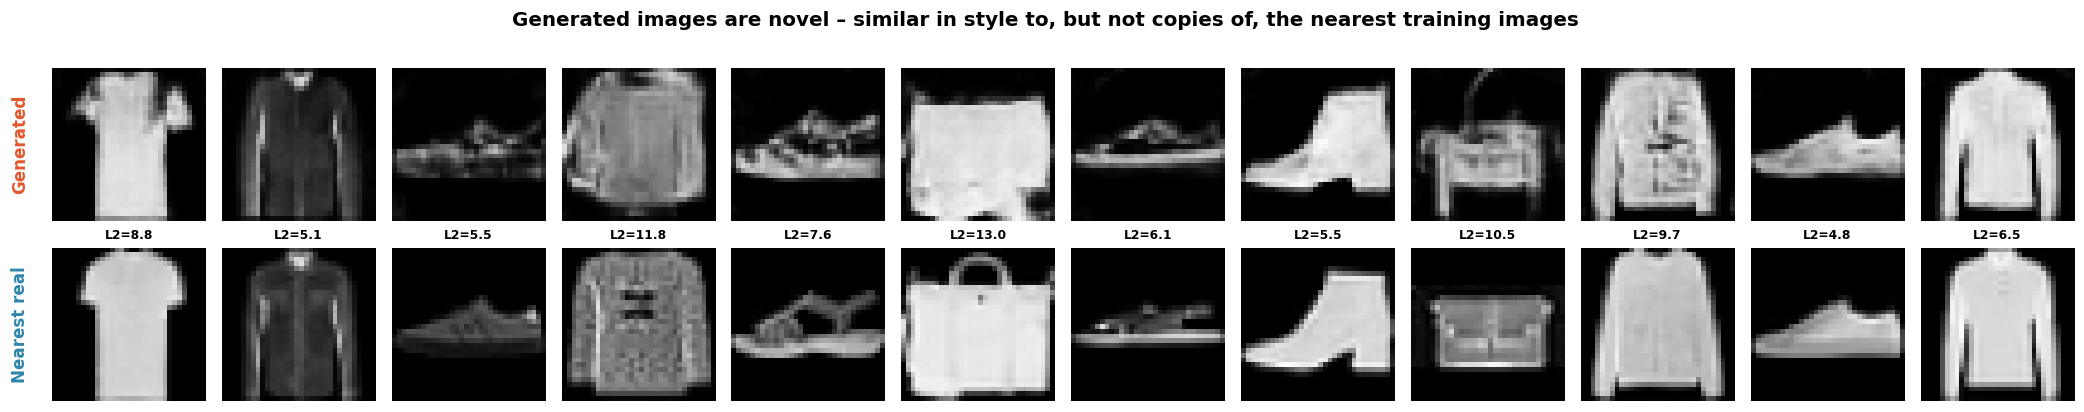

In [ ]:
torch.manual_seed(CFG["SEED"] + 2)
probe = generate(12)
d_mat = torch.cdist(probe.flatten(1), X_train.flatten(1))
nn_idx = d_mat.argmin(1)
fig, axes = plt.subplots(2, 12, figsize=(19, 3.9))
for i in range(12):
    axes[0, i].imshow(((probe[i, 0].cpu() + 1) / 2), cmap="gray", vmin=0, vmax=1); axes[0, i].axis("off")
    axes[1, i].imshow(((X_train[nn_idx[i], 0].cpu() + 1) / 2), cmap="gray", vmin=0, vmax=1); axes[1, i].axis("off")
    axes[1, i].set_title(f"L2={d_mat[i, nn_idx[i]].item():.1f}", fontsize=8)
axes[0, 0].text(-0.15, 0.5, "Generated", transform=axes[0, 0].transAxes, rotation=90, ha="right", va="center", fontsize=11, fontweight="bold", color=PAL["fake"])
axes[1, 0].text(-0.15, 0.5, "Nearest real", transform=axes[1, 0].transAxes, rotation=90, ha="right", va="center", fontsize=11, fontweight="bold", color=PAL["real"])
fig.suptitle("Generated images are novel – similar in style to, but not copies of, the nearest training images", fontsize=13, fontweight="bold")
plt.tight_layout(); savefig("11_nearest_neighbours.png"); plt.show()

<a id="9"></a>
## 9. 3D Analysis

### 9.1 3D intensity surfaces – real vs generated (rotate with the mouse)
Each pixel's brightness is plotted as height. Matching, smooth structure (silhouette, edges, textures) in the generated surface indicates realistic shape synthesis.

In [ ]:
def best_generated_for_class(c):
    m = (pred_fake == c)
    if not m.any(): return int(conf_fake.argmax())
    cand = torch.where(m)[0]
    return int(cand[conf_fake[cand].argmax()])

demo_classes = [CLASS_NAMES.index("Trouser"), CLASS_NAMES.index("Ankle boot")]
fig = make_subplots(rows=2, cols=2, specs=[[{"type": "surface"}] * 2] * 2, vertical_spacing=0.04, horizontal_spacing=0.02,
                    subplot_titles=[f"REAL – {CLASS_NAMES[demo_classes[0]]}", f"GENERATED – {CLASS_NAMES[demo_classes[0]]}",
                                    f"REAL – {CLASS_NAMES[demo_classes[1]]}", f"GENERATED – {CLASS_NAMES[demo_classes[1]]}"])
cam = dict(eye=dict(x=1.5, y=-1.6, z=1.1))
for r_, c in enumerate(demo_classes, start=1):
    real_i = int((y_test == c).nonzero()[0])
    zr = ((X_test[real_i, 0].cpu().numpy() + 1) / 2)
    zf = ((fake_imgs[best_generated_for_class(c), 0].cpu().numpy() + 1) / 2)
    for c_, z_ in zip([1, 2], [zr, zf]):
        fig.add_trace(go.Surface(z=z_, colorscale="Viridis", cmin=0, cmax=1, showscale=False,
                                 contours=dict(z=dict(show=True, usecolormap=True, project=dict(z=True), highlightcolor="white"))), row=r_, col=c_)
fig.update_layout(height=900, template="plotly_white", title="3D pixel-intensity surfaces (height = brightness, floor = contour projection)",
                  margin=dict(l=0, r=0, t=80, b=0))
for k in range(1, 5):
    fig.update_layout({f"scene{k if k > 1 else ''}": dict(camera=cam, zaxis=dict(range=[0, 1], title="Intensity"),
                                                         yaxis=dict(autorange="reversed", title="Row"), xaxis=dict(title="Col"),
                                                         aspectratio=dict(x=1, y=1, z=0.6))})
fig.show()

### 9.2 3D feature-space overlap – real vs generated (interactive)
Both sets are embedded by the classifier's 128-d feature layer and projected to 3D using PCA fitted on **real** data only. Heavy overlap = the generator reproduces the real data manifold; empty real regions = missing modes.

In [ ]:
n_pts = 1500
ri = torch.randperm(len(feat_test))[:n_pts]; fi = torch.randperm(len(feat_fake))[:n_pts]
pca_f = PCA(n_components=3, random_state=CFG["SEED"]).fit(feat_test.cpu().numpy())
Pr = pca_f.transform(feat_test[ri].cpu().numpy()); Pf = pca_f.transform(feat_fake[fi].cpu().numpy())
evf = pca_f.explained_variance_ratio_ * 100

fig = go.Figure()
fig.add_trace(go.Scatter3d(x=Pr[:, 0], y=Pr[:, 1], z=Pr[:, 2], mode="markers", name="Real",
    marker=dict(size=3, color=PAL["real"], opacity=0.55), text=[CLASS_NAMES[i] for i in y_test[ri].cpu().numpy()], hovertemplate="Real: %{text}<extra></extra>"))
fig.add_trace(go.Scatter3d(x=Pf[:, 0], y=Pf[:, 1], z=Pf[:, 2], mode="markers", name="Generated",
    marker=dict(size=3, color=PAL["fake"], opacity=0.55, symbol="diamond"), text=[CLASS_NAMES[i] for i in pred_fake[fi].cpu().numpy()], hovertemplate="Generated: %{text}<extra></extra>"))
fig.update_layout(title=f"Real vs generated in classifier-feature PCA space ({evf.sum():.1f}% variance)", template="plotly_white", height=700,
                  legend=dict(itemsizing="constant", font=dict(size=13)),
                  scene=dict(xaxis_title=f"PC1 ({evf[0]:.1f}%)", yaxis_title=f"PC2 ({evf[1]:.1f}%)", zaxis_title=f"PC3 ({evf[2]:.1f}%)"))
fig.show()

### 9.3 3D evolution of Discriminator scores across training
For every epoch, the distribution of $D(\cdot)$ is plotted for real images (blue) and generated images (red). At epoch 0 the two distributions are far apart; as the Generator improves the red ridge should move toward – and overlap with – the blue one, i.e. the Discriminator can no longer separate them.

In [ ]:
edges = np.linspace(0, 1, 41); centers = (edges[:-1] + edges[1:]) / 2
Zreal = np.array([np.histogram(s, bins=edges, density=True)[0] for s in score_real])
Zfake = np.array([np.histogram(s, bins=edges, density=True)[0] for s in score_fake])
epochs_axis = np.arange(0, E + 1)

fig = go.Figure()
fig.add_trace(go.Surface(x=centers, y=epochs_axis, z=Zreal, colorscale=[[0, "#dcebf6"], [1, "#0b4f7a"]], showscale=False, opacity=0.88, name="D(real)", showlegend=True))
fig.add_trace(go.Surface(x=centers, y=epochs_axis, z=Zfake, colorscale=[[0, "#fbe0d8"], [1, "#9c2a0e"]], showscale=False, opacity=0.88, name="D(generated)", showlegend=True))
fig.update_layout(title="Discriminator output distribution vs epoch  (blue = real, red = generated)", template="plotly_white", height=720,
                  legend=dict(font=dict(size=13)),
                  scene=dict(xaxis_title="D output (prob. 'real')", yaxis_title="Epoch", zaxis_title="Density",
                             camera=dict(eye=dict(x=1.8, y=-1.5, z=0.9))))
fig.show()

### 9.4 Discriminator score distributions – start vs end (2D companion)

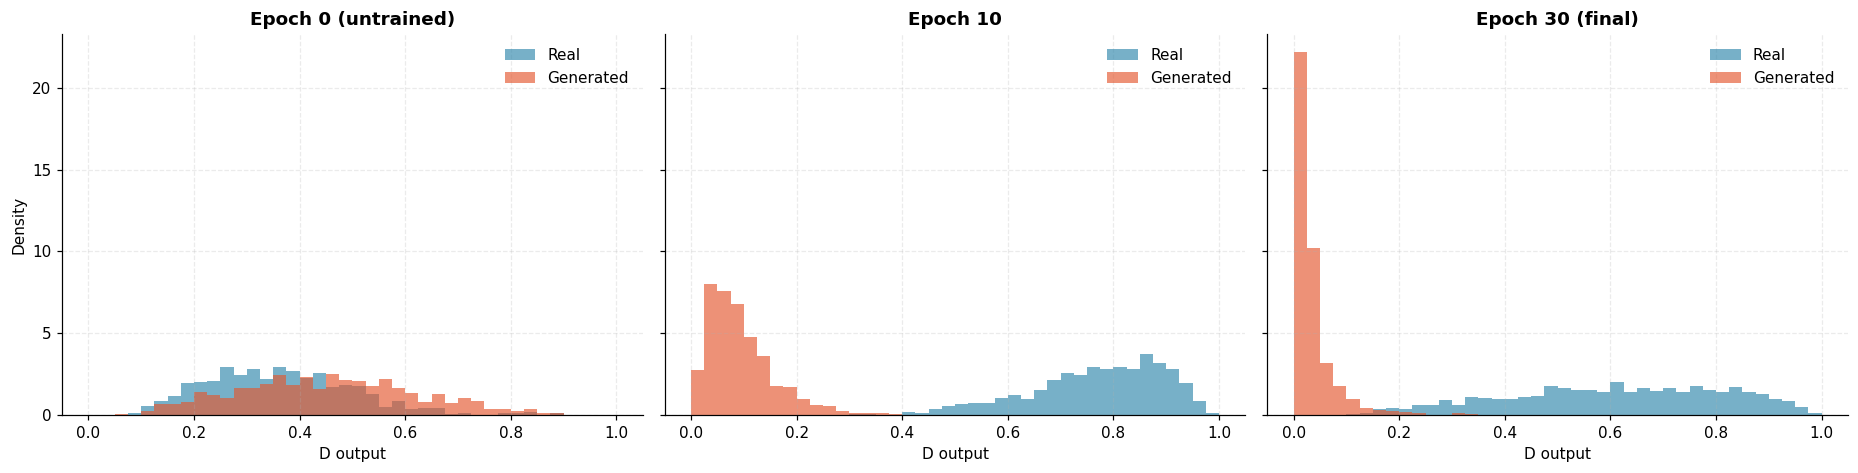

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True)
for ax, e, t in zip(axes, [0, max(1, E // 3), E], ["Epoch 0 (untrained)", f"Epoch {max(1, E // 3)}", f"Epoch {E} (final)"]):
    ax.hist(score_real[e], bins=edges, alpha=0.65, color=PAL["real"], label="Real", density=True)
    ax.hist(score_fake[e], bins=edges, alpha=0.65, color=PAL["fake"], label="Generated", density=True)
    ax.set_title(t); ax.set_xlabel("D output"); ax.legend()
axes[0].set_ylabel("Density")
plt.tight_layout(); savefig("12_discriminator_scores.png"); plt.show()

<a id="10"></a>
## 10. Latent Space Exploration
Smooth transitions between images when moving through latent space show that the Generator has learned a continuous, meaningful representation rather than memorising discrete samples. Spherical linear interpolation (slerp) is used because latent vectors are drawn from a high-dimensional Gaussian.

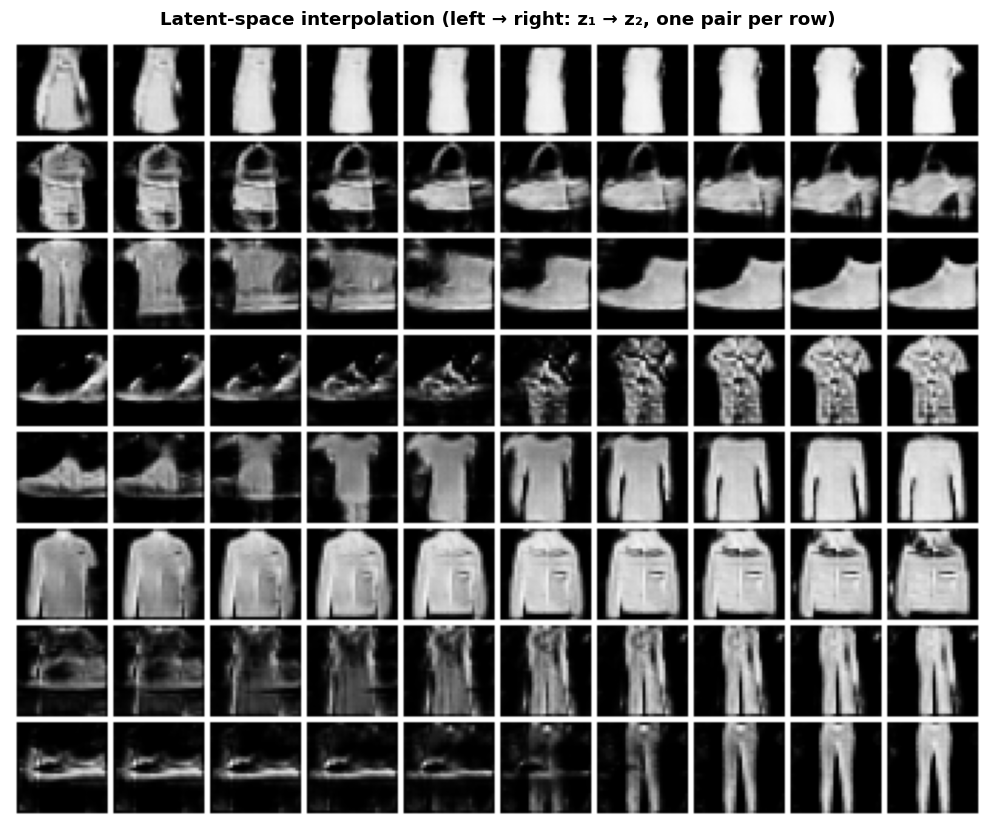

In [ ]:
def slerp(a, b, t):
    a_n, b_n = a / a.norm(), b / b.norm()
    omega = torch.acos((a_n * b_n).sum().clamp(-1 + 1e-7, 1 - 1e-7))
    return (torch.sin((1 - t) * omega) * a + torch.sin(t * omega) * b) / torch.sin(omega)

torch.manual_seed(CFG["SEED"] + 3)
n_rows, n_steps = 8, 10
rows = []
for _ in range(n_rows):
    za, zb = torch.randn(NZ, device=device), torch.randn(NZ, device=device)
    rows.append(torch.stack([slerp(za, zb, t) for t in np.linspace(0, 1, n_steps)]))
z_interp = torch.cat(rows).view(-1, NZ, 1, 1)
imgs_interp = generate(0, z=z_interp)

fig, ax = plt.subplots(figsize=(14, 9.2))
ax.imshow(grid_np(imgs_interp, n_steps, padding=2)); ax.axis("off")
ax.set_title("Latent-space interpolation (left → right: z₁ → z₂, one pair per row)", pad=10)
savefig("13_latent_interpolation.png"); plt.show()

<a id="11"></a>
## 11. Quantitative Summary & Automated Findings

In [ ]:
last = min(5, E)
g_fin, d_fin = np.mean(hist["g_ep"][-last:]), np.mean(hist["d_ep"][-last:])
dx_fin, dgz_fin = np.mean(hist["dx_ep"][-last:]), np.mean(hist["dgz_ep"][-last:])
fd0, fdF = hist["fd_val"][0], hist["fd_val"][-1]
fd_final_full = frechet(feat_test, feat_fake)          # 10,000 vs 10,000
g_std = np.std(hist["g_ep"][-min(10, E):])

summary = pd.DataFrame({
    "Metric": ["Dataset", "Image size", "Epochs / batch size", "Generator parameters", "Discriminator parameters", "Training time (min)",
               f"Final G loss (mean last {last} ep.)", f"Final D loss (mean last {last} ep.)", f"D(x) (mean last {last} ep.)", f"D(G(z)) (mean last {last} ep.)",
               "FD – untrained generator", "FD – trained generator (10k vs 10k)", "FD – real-vs-real floor", "FD improvement vs untrained",
               "Class-coverage entropy (1.0 = uniform)", "Classifier confidence – real / generated"],
    "Value": ["Fashion-MNIST (60k train)", f"{CFG['IMG']}x{CFG['IMG']}x1", f"{E} / {B}", f"{n_g:,}", f"{n_d:,}", f"{TRAIN_TIME/60:.1f}",
              f"{g_fin:.3f}", f"{d_fin:.3f}", f"{dx_fin:.3f}", f"{dgz_fin:.3f}",
              f"{fd0:.2f}", f"{fd_final_full:.2f}", f"{FD_FLOOR:.2f}", f"{(1 - fdF / fd0) * 100:.1f}%",
              f"{class_entropy:.3f}", f"{conf_real.mean():.3f} / {conf_fake.mean():.3f}"]})
display(summary.style.hide(axis="index").set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("background-color", "#2E86AB"), ("color", "white"), ("text-align", "left")]}]))
summary.to_csv(os.path.join(OUT_DIR, "summary_metrics.csv"), index=False)

# ------------------------------ rule-based findings ------------------------------
print("\n" + "=" * 78 + "\nAUTOMATED FINDINGS\n" + "=" * 78)
print(f"1. Convergence  : Frechet distance fell from {fd0:.1f} (untrained) to {fdF:.1f} ({(1 - fdF/fd0)*100:.1f}% reduction); real-vs-real floor is {FD_FLOOR:.1f}.")
ratio = fdF / max(FD_FLOOR, 1e-6)
print("                  " + ("Generated distribution is close to the real-data floor." if ratio < 5 else
      "Generated distribution is clearly improved but still measurably different from real data – longer training or architectural refinements could help."))
if dgz_fin < 0.10:   state = "the Discriminator is dominating (D(G(z)) very low) – Generator gradients may be weak."
elif dgz_fin > 0.60: state = "the Generator is currently fooling the Discriminator heavily – D may be under-powered."
else:                state = "the two networks are in a balanced adversarial equilibrium."
print(f"2. Equilibrium  : D(x)={dx_fin:.2f}, D(G(z))={dgz_fin:.2f} -> {state}")
print(f"3. Stability    : Generator-loss std over last {min(10, E)} epochs = {g_std:.3f} -> " + ("stable plateau." if g_std < 0.25 else "noticeable oscillation (normal for GANs, but worth monitoring)."))
print(f"4. Diversity    : class-coverage entropy = {class_entropy:.3f} -> " + ("no evidence of class-level mode collapse." if class_entropy > 0.95 else
      "some classes are under-represented – possible partial mode collapse."))
print(f"5. Recognisability: classifier confidence on generated images = {conf_fake.mean():.3f} vs {conf_real.mean():.3f} on real images.")
print("6. Novelty      : nearest-neighbour check (Section 8.7) and latent interpolation (Section 10) are used to confirm the model generalises rather than memorises.")

Metric,Value
Dataset,Fashion-MNIST (60k train)
Image size,32x32x1
Epochs / batch size,30 / 128
Generator parameters,"1,066,880"
Discriminator parameters,"661,248"
Training time (min),6.2
Final G loss (mean last 5 ep.),4.211
Final D loss (mean last 5 ep.),0.456
D(x) (mean last 5 ep.),0.854
D(G(z)) (mean last 5 ep.),0.046



AUTOMATED FINDINGS
1. Convergence  : Frechet distance fell from 935.4 (untrained) to 7.6 (99.2% reduction); real-vs-real floor is 0.3.
                  Generated distribution is clearly improved but still measurably different from real data – longer training or architectural refinements could help.
2. Equilibrium  : D(x)=0.85, D(G(z))=0.05 -> the Discriminator is dominating (D(G(z)) very low) – Generator gradients may be weak.
3. Stability    : Generator-loss std over last 10 epochs = 0.154 -> stable plateau.
4. Diversity    : class-coverage entropy = 0.999 -> no evidence of class-level mode collapse.
5. Recognisability: classifier confidence on generated images = 0.810 vs 0.900 on real images.
6. Novelty      : nearest-neighbour check (Section 8.7) and latent interpolation (Section 10) are used to confirm the model generalises rather than memorises.


### 11.1 Save all deliverables

In [ ]:
pd.DataFrame({"epoch": ep_axis, "g_loss": hist["g_ep"], "d_loss": hist["d_ep"], "D_x": hist["dx_ep"], "D_G_z": hist["dgz_ep"]}).to_csv(
    os.path.join(OUT_DIR, "epoch_history.csv"), index=False)
zip_name = f"{CFG['PRN']}_Pr_4_outputs.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in os.listdir(OUT_DIR): zf.write(os.path.join(OUT_DIR, f), f)
print(f"Saved {len(os.listdir(OUT_DIR))} files to '{OUT_DIR}/' and zipped as '{zip_name}'")
try:
    from google.colab import files; files.download(zip_name)
except Exception:
    pass

Saved 18 files to '202401110045_Pr_4_outputs/' and zipped as '202401110045_Pr_4_outputs.zip'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<a id="12"></a>
## 12. Conclusion

* A **DCGAN** (transposed-convolution Generator, strided-convolution Discriminator, BatchNorm, ReLU/LeakyReLU, Adam with β₁ = 0.5) was implemented from scratch in PyTorch and trained adversarially on **Fashion-MNIST**.
* **Training dynamics** were examined through iteration- and epoch-level $L_G$/$L_D$, the Discriminator's confidence on real and generated images, a 3D loss trajectory and a 3D surface showing how the Discriminator's score distributions for real and fake images converge over time.
* **Image quality** was assessed qualitatively (progression grids, animated GIF, real-vs-generated comparison, 3D intensity surfaces, latent interpolation, nearest-neighbour check) and quantitatively (Fréchet Distance in a classifier feature space benchmarked against a real-vs-real floor, pixel statistics, class-coverage entropy, classifier confidence).
* Section 11 contains the data-driven findings for this specific run (convergence, equilibrium, stability, diversity).

**Limitations & future work**
* FD uses a task-specific feature extractor rather than Inception, so values are not comparable with published FID numbers – they are valid for relative comparison inside this notebook.
* Possible improvements: Wasserstein loss with gradient penalty, spectral normalisation, self-attention, exponential moving average of generator weights, class-conditional DCGAN (cDCGAN) for controllable generation, and higher-resolution datasets (CelebA, CIFAR-10).

**References**
1. Radford, Metz & Chintala (2016). *Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks.* ICLR.
2. Goodfellow et al. (2014). *Generative Adversarial Nets.* NeurIPS.
3. Heusel et al. (2017). *GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium.* NeurIPS (Fréchet Inception Distance).
4. Xiao, Rasul & Vollgraf (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms.*